# CA2FL vs FedBuff in the paper's setting

Reproduces the main comparison of Wang et al., *Tackling the Data Heterogeneity in Asynchronous Federated Learning with Cached Update Calibration* (ICLR 2024): CA2FL against FedBuff with **many clients, only some of them active at a time, and strongly non-IID data**.

**How it works**

1. The shared conditions come from `settings.yaml`, and this notebook overrides only the values that define the paper's scenario (table below), **for its own runs only**.
2. Every method uses the paper's client sampling: `CONCURRENCY` clients train at once, and each time an update arrives a random idle client is started.
3. Each method is run with every server rate in `RATES`. Its rate is chosen by **validation** accuracy, then the test results of that rate are reported.
4. Everything is run on 3 seeds.

| Setting | `settings.yaml` | This notebook (paper) |
|---|---|---|
| Clients | 10 | 100 |
| Active at a time (`M_c`) | all | 20 |
| Buffer size (`M`) | 5 | 10 |
| Dirichlet alpha | 0.5 | 0.1 |
| Client updates | 100 | 1000 |

> **Important:** this notebook does **not** change `settings.yaml`, the approach notebooks or `results/`. It saves only three files, in `results/paper_ca2fl/alpha<value>/`: `metrics.csv` (every evaluation of every run), `summary.csv` (the results table) and `accuracy_vs_updates.png`. `compare.ipynb` does not read this folder.

> **Note:** the three methods compared:
> * **CA2FL**: `approaches/ca2fl.ipynb`, unchanged.
> * **FedBuff (paper)**: the paper's baseline (its Algorithm 1). It is CA2FL without the cache: the plain average of the buffered deltas.
> * **FedBuff (staleness weighted)**: `approaches/fedbuff.ipynb`, unchanged. It weights updates by samples / (1 + staleness).

> **Caution:** differences from the paper: the dataset and model are the ones in `settings.yaml` (MNIST with an MLP, not CIFAR-10 with ResNet-18), only 12,000 training images are shared out (about 120 per client), and local training has no weight decay.

## 1. Load the simulator

In [1]:
%run simulator.ipynb
import multiprocessing as mp
import matplotlib.pyplot as plt
plt.style.use("default")

## 2. The paper's setting

> **Tip:** to test the effect of heterogeneity, run again with `dirichlet_alpha=0.3` or `0.5`. Each value is saved in its own folder.

In [2]:
PAPER = dict(num_clients=100, dirichlet_alpha=0.1, max_updates=1000, eval_interval=20)   # overrides, this notebook only
CONCURRENCY = 20                 # clients training at a time (M_c)
BUFFER = 10                      # updates per global step (M)
RATES = [0.5, 1.0]               # server rates tried for every method (chosen on validation)
SEEDS = [42, 43, 44]
PARALLEL = 4                     # runs at the same time, one CPU thread each

OUT = RESULTS / "paper_ca2fl" / f"alpha{PAPER['dirichlet_alpha']}"
PAPER_ID = settings_id(load_settings(**PAPER))
print(f"{PAPER['num_clients']} clients, {CONCURRENCY} active, buffer {BUFFER}, Dir({PAPER['dirichlet_alpha']}), "
      f"{PAPER['max_updates']} updates, seeds {SEEDS}  ->  {OUT.relative_to(ROOT)}")

100 clients, 20 active, buffer 10, Dir(0.1), 1000 updates, seeds [42, 43, 44]  ->  results/paper_ca2fl/alpha0.1


## 3. The methods

CA2FL and the staleness-weighted FedBuff are loaded from their notebooks without changing them. The two FedBuff variants are given the same client sampling as CA2FL, so the only difference between the methods is how the server aggregates.

In [3]:
CA2FL = load_approach("ca2fl")
FedBuffWeighted = load_approach("fedbuff")


class FedBuffPaper(CA2FL):
    """The paper's Algorithm 1: the plain average of the buffered deltas (CA2FL without the cache)."""
    name = "fedbuff_paper"
    label = "FedBuff (paper)"

    def on_update(self, server, update):
        self.buffer.append(update)
        if len(self.buffer) == self.buffer_size:
            server.set_model(apply_delta(server.model, self.buffer, [1.0] * len(self.buffer), self.server_rate), self.buffer)
            self.buffer = []


class FedBuffWeightedSampled(FedBuffWeighted):
    """approaches/fedbuff.ipynb with the paper's client sampling."""
    label = "FedBuff (staleness weighted)"
    concurrency = None
    client_free = CA2FL.client_free

    def start(self, server):
        self.buffer = []
        CA2FL.start(self, server)


METHODS = {"ca2fl": CA2FL, "fedbuff_paper": FedBuffPaper, "fedbuff_weighted": FedBuffWeightedSampled}
LABELS = {"ca2fl": "CA2FL", "fedbuff_paper": "FedBuff (paper)", "fedbuff_weighted": "FedBuff (staleness weighted)"}

## 4. Run

Every (method, server rate, seed) is one run. All runs are kept in **one** table, `metrics.csv`. Runs already in it are **not** re-run, so if the notebook is interrupted, run it again and it continues where it stopped.

> **Note:** this takes about 5 minutes on a 4-core laptop.

In [4]:
import tempfile


def run_one(job):
    method, rate, seed = job
    approach = METHODS[method](buffer_size=BUFFER, concurrency=CONCURRENCY, server_rate=rate)
    with tempfile.TemporaryDirectory() as tmp:     # run() writes per-run CSVs; only the combined table is kept
        m = run(approach, seeds=[seed], overrides=PAPER, results_dir=tmp, name=f"{method}_rate{rate}", verbose=False)
    return m.assign(method=method, rate=rate)


saved = OUT / "metrics.csv"
done = pd.read_csv(saved) if saved.exists() else None
if done is not None:
    done = done[done.settings_id == PAPER_ID]      # runs made with other settings are run again
have = set() if done is None else set(zip(done.method, done.rate, done.seed))
jobs = [(m, r, s) for m in METHODS for r in RATES for s in SEEDS if (m, r, s) not in have]

if jobs:
    OUT.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(1)    # before forking: otherwise every worker inherits the kernel's thread pool and the CPU is oversubscribed
    with mp.get_context("fork").Pool(PARALLEL) as pool:
        new = pool.map(run_one, jobs, chunksize=1)
    done = pd.concat(([done] if done is not None else []) + new, ignore_index=True)
    done.to_csv(saved, index=False)
metrics = done[done.method.isin(list(METHODS)) & done.rate.isin(RATES) & done.seed.isin(SEEDS)]
print(f"{len(jobs)} new run(s), {metrics.groupby(['method', 'rate', 'seed']).ngroups} runs in total")

0 new run(s), 18 runs in total


## 5. Choose each method's server rate (validation)

The score is the mean accuracy over the last 10% of the updates, averaged over seeds. The rate with the best **validation** score is chosen; test accuracy is not used for choosing.

In [5]:
def tail(m):
    return m[m.updates >= 0.9 * m.updates.max()]


scores = (metrics.groupby(["method", "rate", "seed"]).apply(lambda m: tail(m)[["val_accuracy", "accuracy", "worst10_client_acc"]].mean())
          .groupby(["method", "rate"]).mean().mul(100).round(2))
display(scores.rename(columns={"val_accuracy": "val_pct", "accuracy": "test_pct", "worst10_client_acc": "worst10_pct"}))
best_rate = scores.val_accuracy.groupby("method").idxmax().map(lambda i: i[1]).to_dict()
print("chosen server rates:", best_rate)
chosen = pd.concat([metrics[(metrics.method == m) & (metrics.rate == r)] for m, r in best_rate.items()])

val_pct  test_pct  worst10_pct
method           rate                                
ca2fl            0.5     89.47     90.22        84.55
                 1.0     87.01     87.25        73.26
fedbuff_paper    0.5     86.51     87.32        76.90
                 1.0     85.42     85.94        71.98
fedbuff_weighted 0.5     84.01     84.80        69.30
                 1.0     76.39     76.81        51.30

chosen server rates: {'ca2fl': 0.5, 'fedbuff_paper': 0.5, 'fedbuff_weighted': 0.5}


## 6. Results

Test accuracy and worst-10% client accuracy (fairness) at the chosen rates, as mean and standard deviation over seeds. As in the paper, the score is the mean over the last 10% of the updates; `final_test_pct` is the last evaluation only.

> **Note:** `worst10_pct` is the accuracy on the 10% of clients the model serves worst. With strongly non-IID data this is where the cache should help most, because the clients that have not been heard from recently are still represented in every global step.

In [6]:
per_seed = chosen.groupby(["method", "seed"]).apply(lambda m: pd.Series({
    "test": tail(m).accuracy.mean() * 100, "worst10": tail(m).worst10_client_acc.mean() * 100,
    "final_test": m.accuracy.iloc[-1] * 100})).reset_index()
results = per_seed.groupby("method").agg(server_rate=("method", lambda s: best_rate[s.iloc[0]]),
                                         test_pct=("test", "mean"), test_std=("test", "std"),
                                         worst10_pct=("worst10", "mean"), worst10_std=("worst10", "std"),
                                         final_test_pct=("final_test", "mean"))
results = results.loc[list(METHODS)].rename(index=LABELS).round(2)
results.to_csv(OUT / "summary.csv")
display(results)
display(per_seed.pivot(index="seed", columns="method", values="test").rename(columns=LABELS).round(2))

,server_rate,test_pct,test_std,worst10_pct,worst10_std,final_test_pct
method,,,,,,
CA2FL,0.5,90.22,1.24,84.55,1.37,90.33
FedBuff (paper),0.5,87.32,2.13,76.90,3.99,86.10
FedBuff (staleness weighted),0.5,84.80,2.30,69.30,5.51,83.85


method,CA2FL,FedBuff (paper),FedBuff (staleness weighted)
seed,,,
42,91.65,89.75,86.03
43,89.45,85.79,82.15
44,89.57,86.43,86.22


## 7. Curves

Mean over seeds of each evaluation, at the chosen rates. Left: test accuracy against client updates (the paper's x-axis). Right: worst-10% client accuracy.

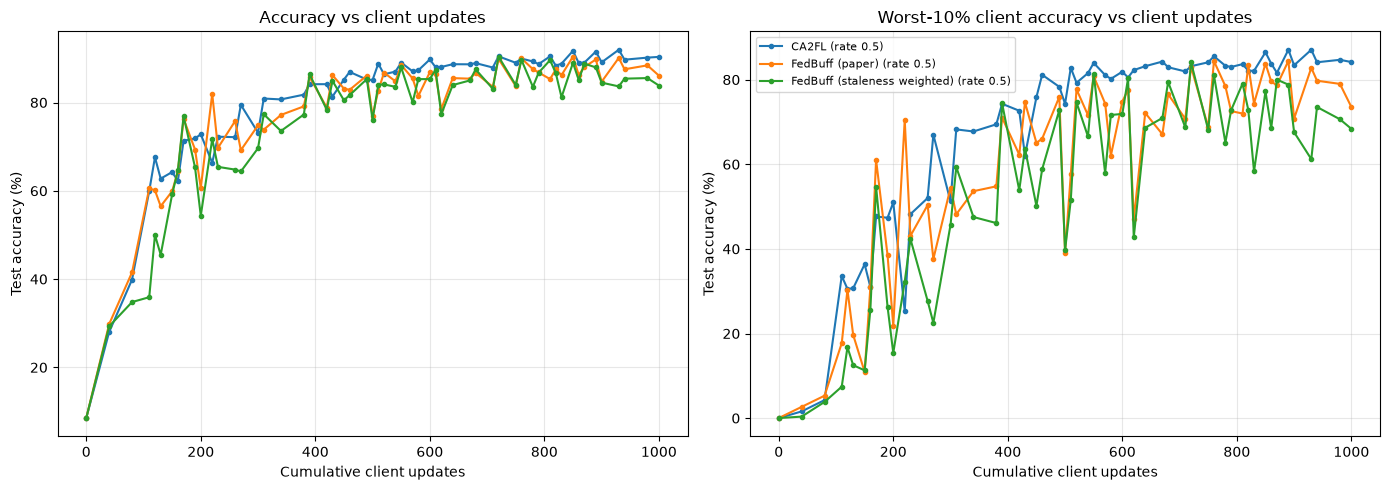

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for method in METHODS:
    c = chosen[chosen.method == method].groupby("version", as_index=False)[["updates", "accuracy", "worst10_client_acc"]].mean()
    label = f"{LABELS[method]} (rate {best_rate[method]})"
    axes[0].plot(c.updates, c.accuracy * 100, marker="o", markersize=3, label=label)
    axes[1].plot(c.updates, c.worst10_client_acc * 100, marker="o", markersize=3, label=label)
axes[0].set(xlabel="Cumulative client updates", ylabel="Test accuracy (%)", title="Accuracy vs client updates")
axes[1].set(xlabel="Cumulative client updates", ylabel="Test accuracy (%)", title="Worst-10% client accuracy vs client updates")
for ax in axes:
    ax.grid(alpha=.3)
axes[1].legend(loc="best", fontsize=8)
plt.tight_layout()
fig.savefig(OUT / "accuracy_vs_updates.png", dpi=150, bbox_inches="tight")
plt.show()